# Outlier Detection & Removal
**Dataset:** UCI Optdigits

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

cols = [f"pixel_{i}" for i in range(64)] + ["target"]

# Load train and test separately - IMPORTANT: never fit any transformer on test data
train = pd.read_csv("../../data/raw/optdigits.tra", header=None, names=cols)
test  = pd.read_csv("../../data/raw/optdigits.tes", header=None, names=cols)

print("Train shape:", train.shape)   # run this code to obtain actual value
print("Test shape:", test.shape)     # run this code to obtain actual value
train.head()

Train shape: (3823, 65)
Test shape: (1797, 65)


,pixel_0,pixel_1,pixel_2,pixel_3,pixel_4,pixel_5,pixel_6,pixel_7,pixel_8,pixel_9,...,pixel_55,pixel_56,pixel_57,pixel_58,pixel_59,pixel_60,pixel_61,pixel_62,pixel_63,target
0,0,1,6,15,12,1,0,0,0,7,...,0,0,0,6,14,7,1,0,0,0
1,0,0,10,16,6,0,0,0,0,7,...,0,0,0,10,16,15,3,0,0,0
2,0,0,8,15,16,13,0,0,0,1,...,0,0,0,9,14,0,0,0,0,7
3,0,0,0,3,11,16,0,0,0,0,...,0,0,0,0,1,15,2,0,0,4
4,0,0,5,14,4,0,0,0,0,0,...,0,0,0,4,12,14,7,0,0,6


In [2]:
# --- Step A: total intensity per row ---
train["total_intensity"] = train.iloc[:, :64].sum(axis=1)
train["total_intensity"].describe()  # run this code to obtain actual value


count    3823.000000
mean      315.134188
std        35.862448
min       202.000000
25%       287.000000
50%       314.000000
75%       341.000000
max       438.000000
Name: total_intensity, dtype: float64

In [3]:
# --- Step B: IQR outlier detection (fit on TRAIN ONLY) ---
Q1 = train["total_intensity"].quantile(0.25)
Q3 = train["total_intensity"].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outlier_mask = (train["total_intensity"] < lower) | (train["total_intensity"] > upper)
print("Outlier bounds:", lower, upper)          # run this code to obtain actual value
print("Number of outlier rows:", outlier_mask.sum())  # run this code to obtain actual value

train_no_outliers = train[~outlier_mask].reset_index(drop=True)
print("Rows before:", train.shape[0], "-> after:", train_no_outliers.shape[0])  # run this code to obtain actual value


Outlier bounds: 206.0 422.0
Number of outlier rows: 3
Rows before: 3823 -> after: 3820


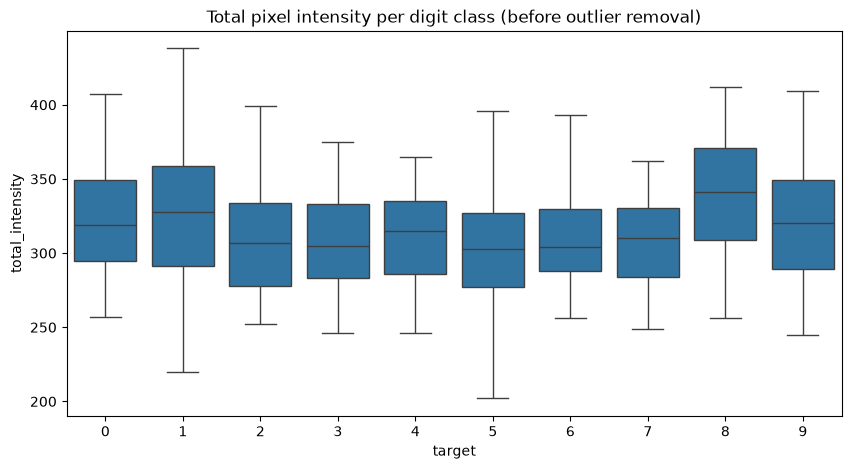

In [ ]:
# --- EDA visualization: boxplot per digit class ---
plt.figure(figsize=(10,5))
sns.boxplot(x="target", y="total_intensity", data=train)
plt.title("Total pixel intensity per digit class (before outlier removal)")
plt.savefig("../../results/eda_visualizations/member2_outlier_boxplot.png", dpi=150, bbox_inches="tight")
plt.show()

## Model Evaluation

Logistic Regression is a compact multiclass baseline for the digit classes. This comparison tests whether removing train-set total-intensity IQR outliers changes performance; test rows remain untouched. MinMax scaling is fitted within each CV fold using a Pipeline, and `GridSearchCV` tunes regularization strength with 5-fold stratified CV. Accuracy and macro F1 are reported on CV and the official held-out test set; macro F1 weights every digit equally.

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler

feature_cols = [f"pixel_{index}" for index in range(64)]
y_test = test["target"].astype(int)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
training_variants = {
    "Before IQR outlier removal": train,
    "After IQR outlier removal": train_no_outliers,
}
results = []
for variant_name, variant_data in training_variants.items():
    model = Pipeline([
        ("scaler", MinMaxScaler()),
        ("classifier", LogisticRegression(max_iter=2000, random_state=42)),
    ])
    search = GridSearchCV(
        model,
        {"classifier__C": [0.1, 1, 10]},
        scoring={"accuracy": "accuracy", "macro_f1": "f1_macro"},
        refit="macro_f1",
        cv=cv,
        n_jobs=-1,
    )
    search.fit(variant_data[feature_cols], variant_data["target"].astype(int))
    predictions = search.predict(test[feature_cols])
    results.append({
        "Training data": variant_name,
        "CV accuracy": search.cv_results_["mean_test_accuracy"][search.best_index_],
        "CV macro F1": search.best_score_,
        "Test accuracy": accuracy_score(y_test, predictions),
        "Test macro F1": f1_score(y_test, predictions, average="macro"),
        "Best parameters": search.best_params_,
    })

outlier_model_comparison = pd.DataFrame(results).sort_values(
    "CV macro F1", ascending=False
).reset_index(drop=True)
display(outlier_model_comparison)

,Training data,CV accuracy,CV macro F1,Test accuracy,Test macro F1,Best parameters
0,After IQR outlier removal,0.971728,0.971796,0.952142,0.952224,{'classifier__C': 10}
1,Before IQR outlier removal,0.971228,0.971233,0.952699,0.952761,{'classifier__C': 10}


### Results and viva conclusion

The train-only IQR rule removed 3 of 3,823 training examples. After-removal CV macro F1 was 97.18%, slightly above 97.12% before removal, but test macro F1 was 95.22%, slightly below 95.28% before removal. The effect is small and mixed, so this experiment does not show that outlier removal improves unseen-data performance. The official test rows were retained unchanged, and scaling was fitted within CV folds. Limitations include using total intensity as a one-dimensional outlier rule and evaluating on one official test split; future work could inspect the removed examples and compare robust models or alternative outlier definitions.